# Continuous Optimization in Data Science: Assignment 1

**Group 3**

**Group members:**
- Simon Carlén
- Alvin Stallgård

## Q1.1 Gaussian models

**(a)**

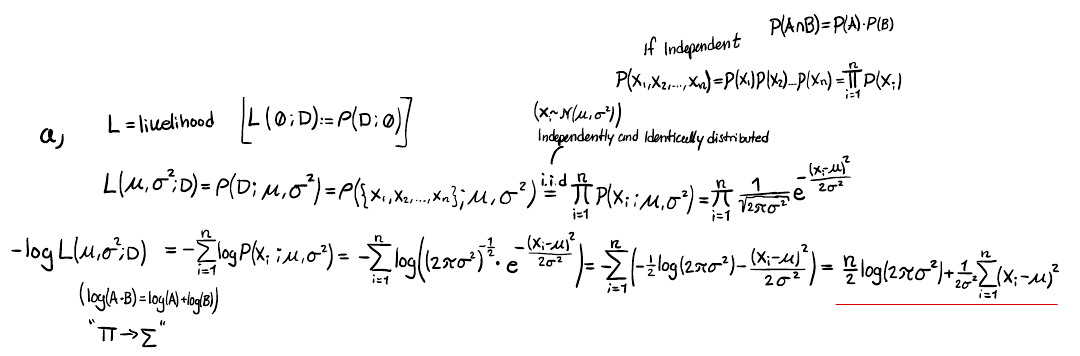

**(b)**

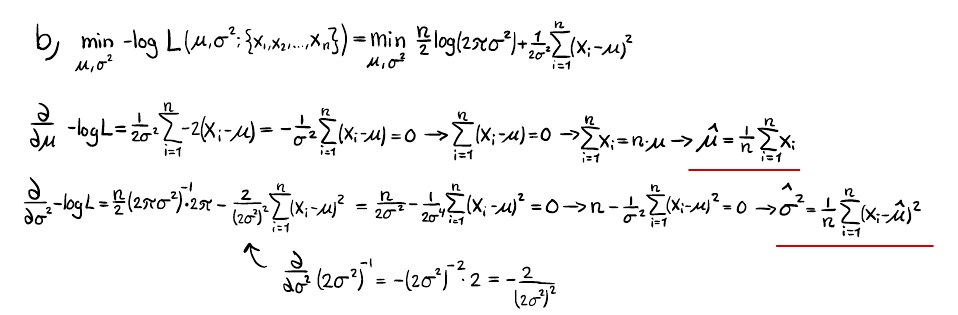

**(c)**

$\mu$ is the mean grade of the students and $\sigma^2$ is the variance of the grades.

$\mu$ tells us how hard the test was. If it's close to the max the test was too easy, and if it's close to 0 it was too hard. So a $\mu$ somewhere in the middle is good, maybe a bit above the passing grade.

$\sigma^2$ tells us how spread out the grades are. If it's small, everyone got about the same grade and the test doesn't really separate the students who know the material from the ones who don't. So we want a fairly large $\sigma^2$, but not too large. Since grades are bounded, $\mu \pm 3\sigma$ should lie within $[0, \text{max}]$. Otherwise the Gaussian assumption breaks down, and the test would be badly calibrated.

## Q1.2 Linear regression

**(a)**

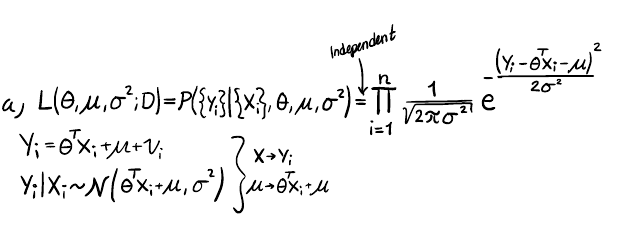

**(b)**

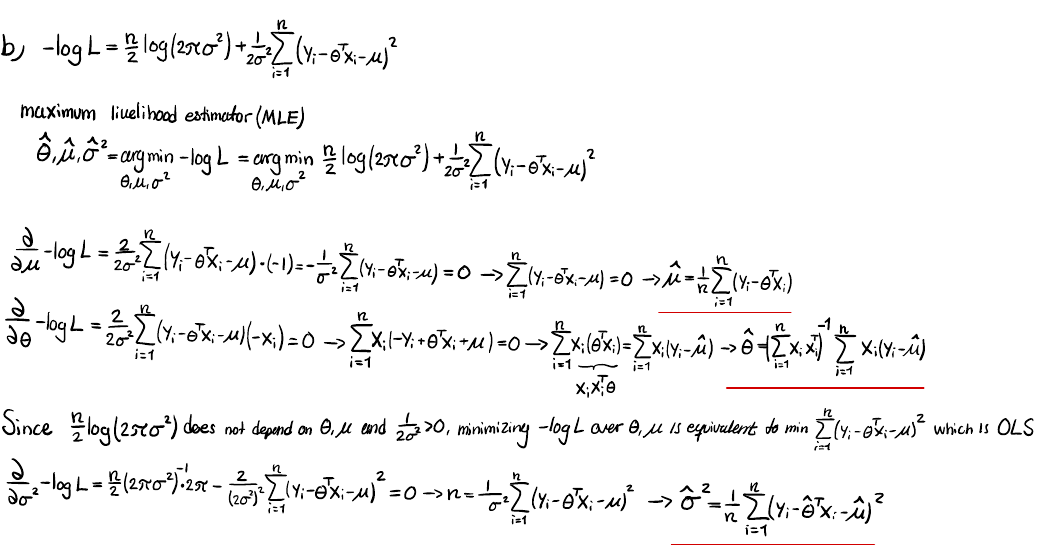

**(c)**

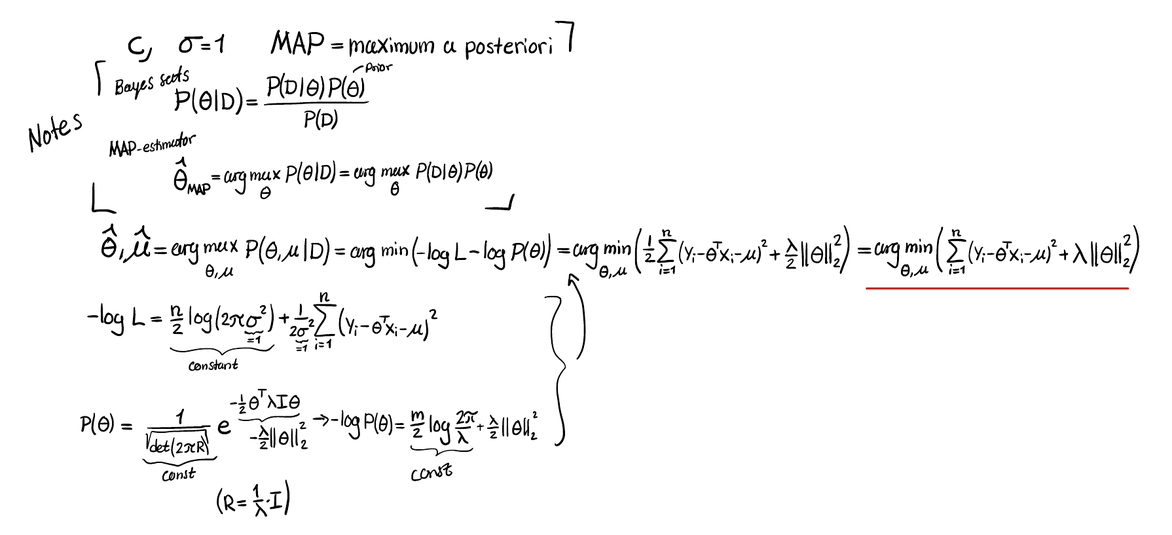

We assume a flat prior on $\mu$ (independent of $\theta$), so $P(\theta, \mu \mid D) \propto P(D \mid \theta, \mu)\,P(\theta)$. $P(D)$ doesn't depend on $\theta$ or $\mu$, so it can be dropped. Since $\mu$ has no prior, only $\theta$ gets regularized.

### (d) OLS and ridge regression on the house pricing data

In [1]:
import pandas
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

In [2]:
data0 = pandas.read_csv('Real estate.csv')
npdata = data0.to_numpy()

variables = npdata[:, 1:7]
variables = np.hstack([variables, np.ones((variables.shape[0], 1))])  # ones column -> its weight is the intercept
label = npdata[:, 7]

In [3]:
# alpha=0 gives the maximum likelihood (OLS) solution
model = Ridge(alpha=0, fit_intercept=False).fit(variables, label)
sigma = np.sqrt(np.mean((label - variables @ model.coef_) ** 2))
print(model.coef_)
print(sigma)

[ 5.14622774e+00 -2.69695447e-01 -4.48746099e-03  1.13327691e+00
  2.25472976e+02 -1.24235922e+01 -1.44371025e+04]
8.782466464602711


In [4]:
# Ridge regression with increasing alpha
for alpha in [0, 1, 100, 10000, 1000000]:
    model = Ridge(alpha=alpha, fit_intercept=False).fit(variables, label)
    sigma = np.sqrt(np.mean((label - variables @ model.coef_) ** 2))
    print(alpha, model.coef_, sigma)

0 [ 5.14622774e+00 -2.69695447e-01 -4.48746099e-03  1.13327691e+00
  2.25472976e+02 -1.24235922e+01 -1.44371025e+04] 8.782466464602711
1 [ 6.00702211e-01 -2.53872134e-01 -5.47101395e-03  1.28540141e+00
  7.16096396e+00 -1.10659135e+01 -8.33248073e-02] 9.157291661693822
100 [ 2.81581717e-02 -2.51504875e-01 -5.45875191e-03  1.24199153e+00
  7.39599406e-02 -1.25607258e-01 -9.21298109e-04] 9.205845912061683
10000 [ 2.38173625e-02 -1.98047791e-01 -6.88306876e-03  2.37069188e-01
  1.12527213e-03  1.59438394e-05  1.73409330e-06] 9.543158546079797
1000000 [ 2.27536146e-02 -1.15650945e-02 -7.22627987e-03  2.81023307e-03
  2.90182824e-04  1.35984307e-03  1.12017603e-05] 10.00770558405495


#### 2012 vs 2013

In [5]:
year = np.floor(variables[:, 0])
for y in [2012, 2013]:
    model = Ridge(alpha=0, fit_intercept=False).fit(variables[year == y], label[year == y])
    sigma = np.sqrt(np.mean((label[year == y] - variables[year == y] @ model.coef_) ** 2))
    print(y, model.coef_, sigma)

2012 [-3.58205820e+00 -4.28609585e-01 -4.52214020e-03  1.14845666e+00
  2.11170977e+02 -2.99898064e+01  5.62558341e+03] 6.1495963705770285
2013 [ 4.77673643e+00 -1.97957137e-01 -4.33163675e-03  1.12793625e+00
  2.37827393e+02 -3.62701939e-01 -1.54688222e+04] 9.579671015412801


In [6]:
# Numbers used in the report
X = npdata[:, 1:7]

# i. coefficients times the std of each variable
theta = Ridge(alpha=0, fit_intercept=False).fit(variables, label).coef_
print(theta[:6] * X.std(axis=0))

# ii. without the intercept
model = Ridge(alpha=0, fit_intercept=False).fit(X, label)
print(model.coef_, np.sqrt(np.mean((label - X @ model.coef_) ** 2)))

# iv. with fit_intercept=True, so the intercept is not penalized
model = Ridge(alpha=1, fit_intercept=True).fit(X, label)
print(model.intercept_)

# v. number of transactions per year
print((year == 2012).sum(), (year == 2013).sum())

[ 1.44931408 -3.06878822 -5.65682326  3.33410316  2.79478248 -0.19043673]
[ 3.74005214e+00 -2.70810191e-01 -5.49449019e-03  1.12902867e+00
  2.03314226e+02 -1.03360354e+02] 8.83131386034255
-11250.041782976079
126 288


#### Report

**i. What do we learn from $\hat\theta$? Which variable is most important?**

Price goes down with house age and distance to the MRT station, and up with the number of convenience stores nearby. The raw coefficients can't be compared directly since the variables have different units, so we multiplied each coefficient by the standard deviation of its variable. Distance to the MRT then has the largest effect (about $-5.7$, compared to $+3.3$ for convenience stores and $-3.1$ for house age), so it's the most important variable in the pricing.

**ii. Is the intercept $\mu$ important? What happens if we ignore it?**

Yes. Without the intercept the model is forced through the origin, which doesn't make sense here since no house has date 0 or latitude 0. If we remove it, $\hat\sigma$ only goes up slightly (8.78 to 8.83), because the date, latitude and longitude are almost constant (around 2013, 25 and 121.5) and can work as an intercept instead. It's mostly the longitude that takes over, which is why its coefficient goes from $-12$ to $-103$.

**iii. What does $\hat\sigma$ mean? Is it better for it to be small or big?**

$\hat\sigma$ is the standard deviation of the noise, i.e. how much the price typically differs from the model's prediction. Here it's about 8.8, while the mean price is about 38. A small $\hat\sigma$ is better since it means the model fits the data well.

**iv. How do $\hat\theta$ and $\hat\sigma$ change with increasing $\lambda$?**

As $\lambda$ increases, the coefficients shrink towards zero. The intercept goes from $-14437$ to almost 0 already at $\lambda = 1$. Since $\mu$ is a column of ones in $X$, Ridge also penalizes $\mu$, which eq. (5) doesn't. That's why the intercept drops so fast. With fit_intercept=True it's still about $-11250$ at $\lambda = 1$. Not every coefficient shrinks though. The MRT coefficient actually grows from $-0.0045$ to $-0.0072$, and at $\lambda = 10^6$ the date coefficient takes over as the intercept ($0.023 \cdot 2013 \approx 46$). The penalty depends on the scale of the variables, so variables with large values only need small coefficients and barely get penalized. $\hat\sigma$ increases with $\lambda$ since the fit gets worse, from 8.78 at $\lambda = 0$ to about 10 at $\lambda = 10^6$.

**v. Differences between 2012 and 2013? Are per-year models more reliable?**

Yes, $\hat\sigma$ is lower in 2012 (6.1) than in 2013 (9.6), so the prices in 2013 are harder to predict. Distance to the MRT and convenience stores have about the same effect in both years, but house age matters about twice as much in 2012 ($-0.43$ vs $-0.20$). The date, longitude and intercept change a lot. The per-year models fit their own data better, but they're trained on fewer points (126 and 288 instead of 414), so we don't think they're more reliable than one model for the whole dataset.

## Q1.3 Gaussian graphical model

**(a)**

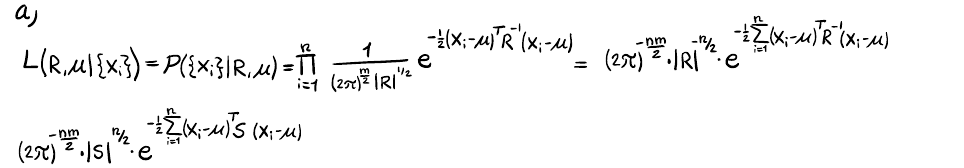

**(b)**

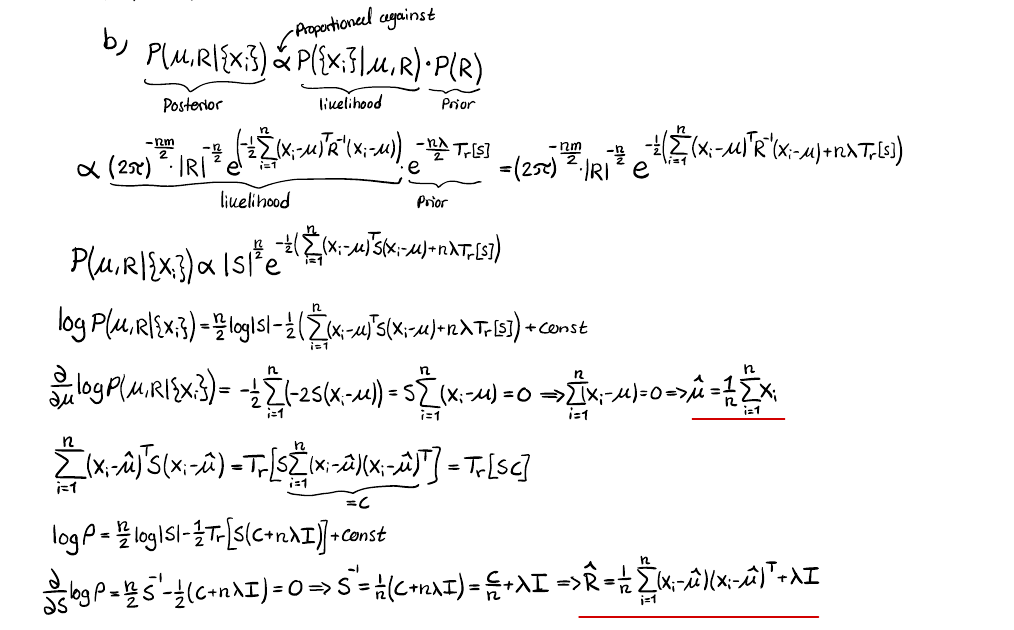

The assignment writes the prior both as $e^{-\lambda \operatorname{Tr}[R^{-1}]}$ and as $e^{-\frac{n\lambda}{2}\operatorname{Tr}[S]}$. We used the second one, which gives eq. (7). Like in Q1.2 we assume a flat prior on $\mu$.

## Q1.4 Gene data

Data: https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.BRCA.sampleMap%2FGistic2_CopyNumber_Gistic2_all_data_by_genes.gz

In [7]:
import networkx as nx

data = pandas.read_csv('TCGA.BRCA.sampleMap_Gistic2_CopyNumber_Gistic2_all_data_by_genes.gz', sep='\t')
gene_names = data['Gene Symbol'].to_numpy()
data_clean = data.iloc[:, 1:].to_numpy(dtype=float)  # (genes, patients)
print(data_clean.shape)

(24776, 1080)


In [8]:
lam = 0.1
t = 0.5
n_genes = 100

mean_genes = data_clean.mean(axis=1)
var_genes = data_clean.var(axis=1)

# Select 100 genes (two methods)
first_100_genes = data_clean[:n_genes]
top_var_idx = np.argsort(var_genes)[::-1][:n_genes]
highest_var_genes = data_clean[top_var_idx]

covariance_matrix = ((first_100_genes - first_100_genes.mean(axis=1, keepdims=True)) @ (first_100_genes - first_100_genes.mean(axis=1, keepdims=True)).T)/first_100_genes.shape[1] + lam * np.eye(n_genes)
precision_matrix = np.linalg.inv(covariance_matrix)

print(covariance_matrix.shape)

(100, 100)


In [9]:
# Rank of the covariance without lambda
for idx in [np.arange(n_genes), top_var_idx]:
    centered = data_clean[idx] - data_clean[idx].mean(axis=1, keepdims=True)
    print(np.linalg.matrix_rank(centered @ centered.T / centered.shape[1]))

# Genes with the largest mean
print(gene_names[np.argsort(mean_genes)[::-1][:5]])

20
98
['MYC' 'CASC8' 'PVT1' 'POU5F1B' 'TRPS1']


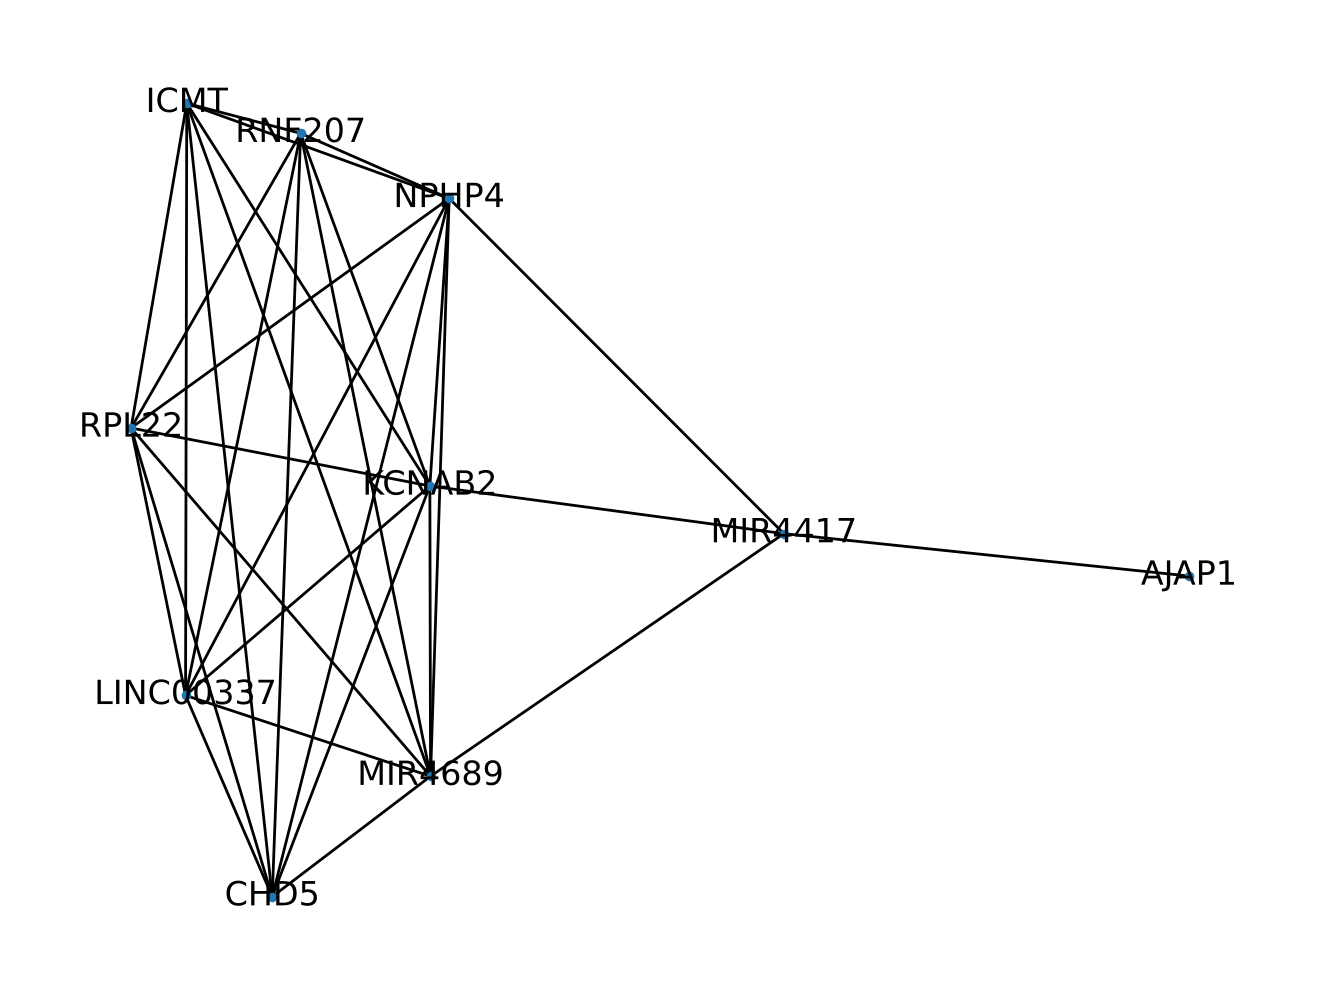

In [10]:
# Add edges to the graph by your precision matrix with graph.add_edge():
# https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.add_edge.html
graph = nx.Graph()
names = gene_names[:n_genes]

for j in range(n_genes):
    for i in range (j + 1, n_genes):
        if abs(precision_matrix[i, j]) > t:
            graph.add_edge(names[i], names[j])

nx.draw(graph, with_labels=True, node_size=6)
plt.show()

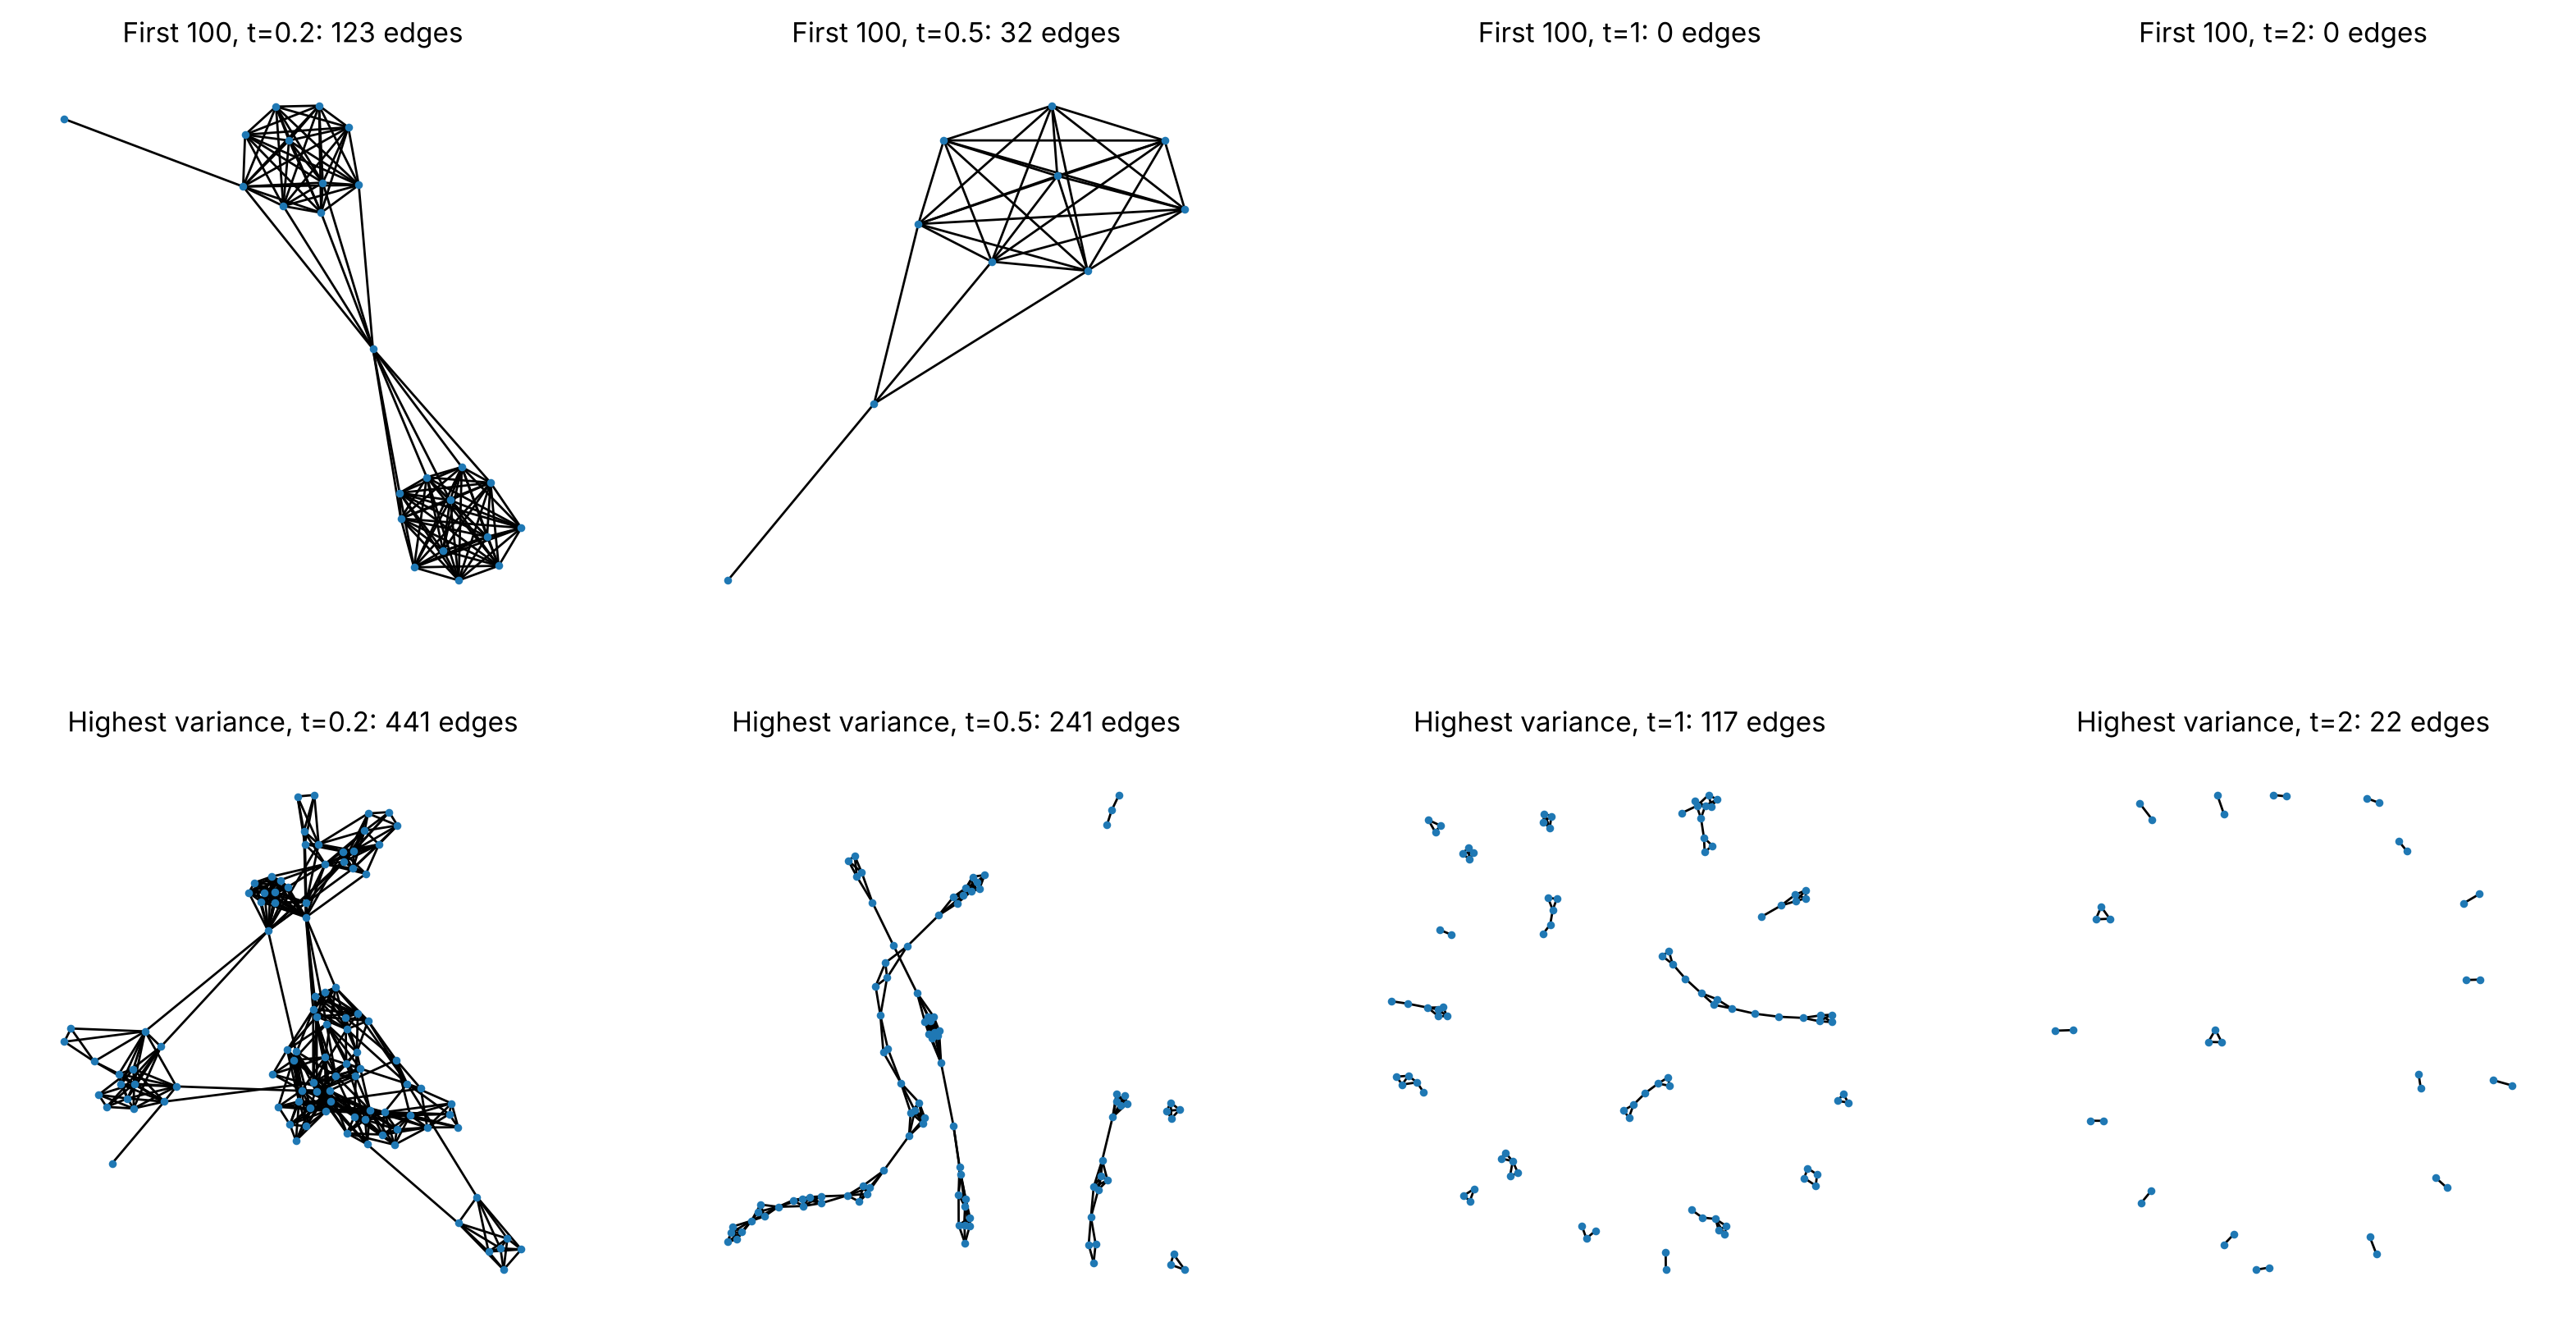

In [11]:
thresholds = [0.2, 0.5, 1, 2]
fig, axes = plt.subplots(2, len(thresholds), figsize=(20, 10))
for row, (title, idx) in enumerate([('First 100', np.arange(n_genes)), ('Highest variance', top_var_idx)]):
    genes = data_clean[idx]
    centered = genes - genes.mean(axis=1, keepdims=True)
    S = np.linalg.inv(centered @ centered.T / genes.shape[1] + lam * np.eye(n_genes))
    for col, thr in enumerate(thresholds):
        g = nx.Graph()
        for j in range(n_genes):
            for i in range(j + 1, n_genes):
                if abs(S[i, j]) > thr:
                    g.add_edge(gene_names[idx][i], gene_names[idx][j])
        nx.draw(g, ax=axes[row, col], with_labels=False, node_size=6, font_size=5)
        axes[row, col].set_title(f'{title}, t={thr}: {g.number_of_edges()} edges')
plt.show()

#### Report

**(a) Effect of $\lambda$. Can it be zero? Why not, and when can it?**

$\lambda$ is added to the diagonal of the covariance, which makes it invertible. A bigger $\lambda$ makes the values in $\hat S$ smaller, so we get fewer edges for the same threshold. We can't set $\lambda = 0$ here since the covariance is singular. A lot of the genes have exactly the same values, so the covariance only has rank 20 for the first 100 genes and rank 98 for the top variance genes (out of 100). $\lambda = 0$ only works if there are more patients than genes and no gene is a linear combination of the others.

**(b) How the threshold is selected.**

We looked at the values in $\hat S$ and picked $t$ so the graph isn't almost fully connected or empty, just keeping the strongest connections. $t$ depends on $\lambda$ since $\lambda$ changes the scale of $\hat S$. We used $t = 0.5$.

**(c) Comparing the two gene selections.**

The first 100 genes are next to each other on the same chromosome, so they're almost identical and have low variance. Their graph is just a few clumps and doesn't say much. The top variance genes are more interesting, and the graph has more edges and groups that make more sense.

**(d) Results for several thresholds.**

See the plots above. A small $t$ gives a mess where almost everything is connected, and a bigger $t$ removes edges until only the strongest ones are left. For the first 100 genes everything is gone already around $t = 1$, while the top variance genes still have some edges at $t = 2$.

**(e) What does a big mean value $\hat\mu$ imply?**

The data is copy number, so a big mean means the gene has extra copies in many of the patients. That suggests the gene might be involved in the cancer. The highest means are MYC and the genes right next to it on chromosome 8 (CASC8, PVT1, POU5F1B), so it's the whole region that has extra copies. The mean doesn't affect the graph though, since we subtract it before computing the covariance.

## Q2.1 LP dual

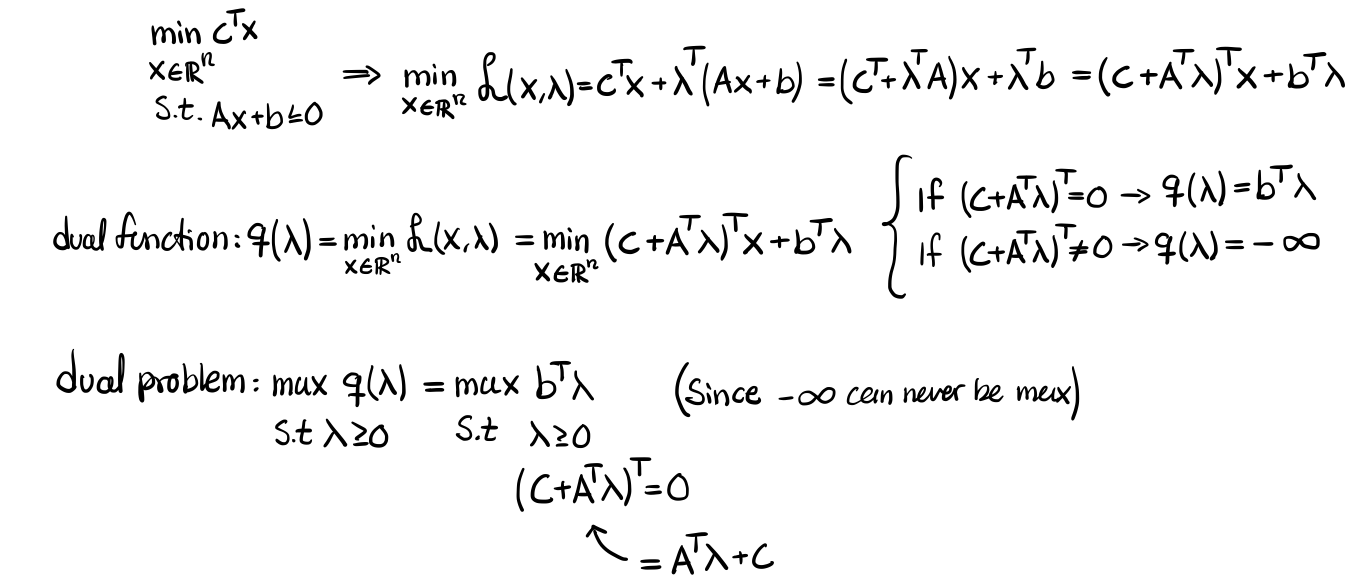

We need $\lambda \ge 0$ because for a feasible $x$ we have $Ax + b \le 0$, so $\lambda^T(Ax + b) \le 0$ and $\mathcal{L}(x, \lambda) \le c^T x$. That means $q(\lambda)$ is a lower bound on the optimal value (weak duality), and the dual problem looks for the best lower bound.